In [59]:
import numpy as np
import matplotlib.pyplot as plt
from ForTP3 import *
from monte_carlo_control import *



In [60]:
def process_episode(episode_t):
    state, action, reward, next_state = episode_t
    state = (int(state[0]), int(state[1]))  
    state = states.index(state)  
    action = actions.index(action)  
    next_state = (int(next_state[0]), int(next_state[1]))  
    next_state = states.index(next_state)  
    return state, action, reward, next_state

def generate_valide_episode(init_states, actions, Maze, exit_state, max_iter=1000):
    valid_episode = False
    while not valid_episode:
        try:
            init_state = init_states[np.random.randint(len(init_states))]
            episode = generate_episode(init_state, actions, Maze, exit_state, itermax=max_iter)
            valid_episode = True
            # print(".", end="")
        except IndexError:
            continue
    return episode


def plot_policy(Maze, states, actions, pi):
    direction_map = {
        'UP': '↑',
        'RIGHT': '→',
        'DOWN': '↓',
        'LEFT': '←'
        
    }
    policy_grid = np.full((len(Maze), len(Maze[0])), ' ')
    _,  exit_state, _ = get_states_from_Maze(Maze)
    for s in range(len(states)):
        best_action = pi[s]
        print(f"State: {states[s]}, Best Action: {actions[best_action]}")
        state_coords = states[s]
        policy_grid[state_coords] = direction_map[actions[best_action]]  # Use the first letter of the action
        if states[s][0] == exit_state[0] and states[s][1] == exit_state[1]:  # If it's the exit state, no action is needed
            policy_grid[state_coords] = 'E'  # Mark the exit state with 'E'
    plt.imshow(Maze, cmap='gray')
    for i in range(len(Maze)):
        for j in range(len(Maze[0])):
            plt.text(j, i, policy_grid[i][j], ha='center', va='center', color='red')
    plt.show()


In [61]:

try:
    with open('maze.pkl', 'rb') as f:
        Maze = pickle.load(f)
except FileNotFoundError:
    # create a new maze if the file does not exist
    app = App()
    app.mainloop()
    Maze=app.A

    # Save the generated maze
    with open('maze.pkl', 'wb') as f:
        pickle.dump(Maze, f)





states,exit_state,init_states = get_states_from_Maze(Maze)
states = list(map(lambda x: (int(x[0]), int(x[1])), states))  # Convert states to a list of tuples for consistent indexing
init_state = init_states[np.random.randint(len(init_states))]
try :
    with open('episode.pkl', 'rb') as f:
        episode = pickle.load(f)
except FileNotFoundError:
    # create a new episode if the file does not exist
    episode = generate_episode(init_state, actions, Maze, exit_state, itermax=100*len(states))

# Save the generated episode
with open('episode.pkl', 'wb') as f:
    pickle.dump(episode, f)


for step in episode:
    print(step)

    

(array([8, 6]), 'UP', 0, array([7, 6]))
(array([7, 6]), 'UP', 0, array([6, 6]))
(array([6, 6]), 'UP', 0, array([5, 6]))
(array([5, 6]), 'DOWN', 0, array([6, 6]))
(array([6, 6]), 'DOWN', 0, array([7, 6]))
(array([7, 6]), 'UP', 0, array([6, 6]))
(array([6, 6]), 'UP', 0, array([5, 6]))
(array([5, 6]), 'UP', 0, array([4, 6]))
(array([4, 6]), 'DOWN', 0, array([5, 6]))
(array([5, 6]), 'DOWN', 0, array([6, 6]))
(array([6, 6]), 'UP', 0, array([5, 6]))
(array([5, 6]), 'DOWN', 0, array([6, 6]))
(array([6, 6]), 'DOWN', 0, array([7, 6]))
(array([7, 6]), 'DOWN', 0, array([8, 6]))
(array([8, 6]), 'DOWN', 0, array([9, 6]))
(array([9, 6]), 'DOWN', 0, array([10,  6]))
(array([10,  6]), 'LEFT', 0, array([10,  5]))
(array([10,  5]), 'LEFT', 0, array([10,  4]))
(array([10,  4]), 'RIGHT', 0, array([10,  5]))
(array([10,  5]), 'LEFT', 0, array([10,  4]))
(array([10,  4]), 'LEFT', 0, array([10,  3]))
(array([10,  3]), 'LEFT', 0, array([10,  2]))
(array([10,  2]), 'RIGHT', 0, array([10,  3]))
(array([10,  3])

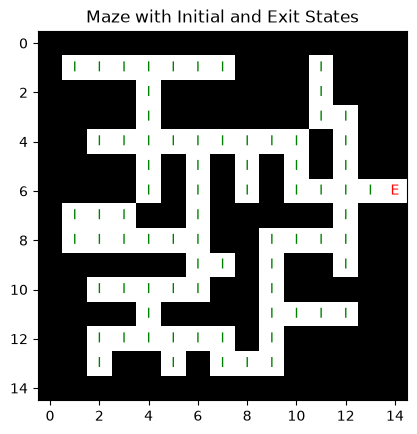

In [62]:
plt.imshow(Maze, cmap='gray')
for state in init_states:
    plt.text(state[1], state[0], 'I', ha='center', va='center', color='green')
plt.text(exit_state[1], exit_state[0], 'E', ha='center', va='center', color='red')
plt.title('Maze with Initial and Exit States')
plt.show()

# Monte Carlo Methods

## First-visit MC prediction

In [63]:
actions = ['UP', 'RIGHT', 'DOWN', 'LEFT']

In [64]:
def get_greedy_policy(q_s_a):
    # Get the greedy policy from Q(s,a)
	pi = np.zeros(len(q_s_a), dtype=int)



	for s in range(len(states)):
		if states[s][0] == exit_state[0] and states[s][1] == exit_state[1]:  # If it's the exit state, no action is needed
			pi[s] = 0  # Indicate no action for the exit state
			continue
		possible_actions = get_actions(states[s], actions, Maze)
		possible_q_values = [actions.index(a) for a in possible_actions]
		action_pi = { a: q_s_a[s][a] for a in possible_q_values }

		pi[s] = max(action_pi, key=action_pi.get)  # Choose the action with the highest Q-value
	return pi

def get_epsilon_greedy_policy(q_s_a, states, epsilon):
	pi = np.zeros(len(q_s_a))
	
	for s in range(len(states)):
		if states[s][0] == exit_state[0] and states[s][1] == exit_state[1]:  # If it's the exit state, no action is neede
			pi[s] = 0  # Indicate no action for the exit state
			continue
		possible_actions = get_actions(states[s], actions, Maze)
		possible_q_values = [actions.index(a) for a in possible_actions]
		action_pi = { a: q_s_a[s][a] for a in possible_q_values }
		
		if np.random.rand() < epsilon:
			pi[s] = np.random.choice(possible_q_values)  # Explore: choose a random action
		else:
			pi[s] = max(action_pi, key=action_pi.get)  # Exploit: choose the action with the highest Q-value
			
		return pi

def generate_random_e_soft_policy(states, actions, epsilon):
	pi = np.zeros(len(states), dtype=int)
	for s in range(len(states)):
		if states[s][0] == exit_state[0] and states[s][1] == exit_state[1]:  # If it's the exit state, no action is needed
			pi[s] = 0  # Indicate no action for the exit state
			continue
		possible_actions = get_actions(states[s], actions, Maze)
		possible_q_values = [actions.index(a) for a in possible_actions]
		if np.random.rand() < epsilon:
			pi[s] = np.random.choice(possible_q_values)  # Explore: choose a random action
		else:
			pi[s] = np.random.choice(possible_q_values)  # Exploit: choose a random action (since we don't have Q-values yet)
	return pi

In [65]:

def generate_episode_from_policy(init_state,actions,Maze,exit_state,pi=None,iter_max=1000):
    #from init_state to exit_state in maze M
    # list of (state, action, reward, next_state)
    # pi is a policy mapping states to action indice
    states, exit_state, init_states = get_states_from_Maze(Maze)
    states = list(map(lambda x: (int(x[0]), int(x[1])), states))  # Convert states to a list of tuples for consistent indexing
    i=0
    current_state = np.copy(init_state)
    s = states.index((current_state[0], current_state[1]))
    episode = list()
    
    while  i < iter_max and not all(current_state == exit_state)  :      
        current_actions = get_actions(current_state,actions,Maze)
        if pi is None:
            action = np.random.choice(current_actions)
        else:
            action = pi[s]
            if action not in current_actions:
                action = np.random.choice(current_actions)
                
        new_state, reward= next_state(current_state, action, exit_state, Maze)
        episode.append((current_state,action, reward, new_state))
        current_state = new_state
        s = states.index((current_state[0], current_state[1]))
        i=i+1
    if current_state[0]== exit_state[0] and current_state[1] == exit_state[1]:
        return episode
    return []


init_state = init_states[np.random.randint(len(init_states))]
pi = np.random.randint(len(actions), size=len(states))  # Random policy for demonstration
generate_episode_from_policy(init_state, actions, Maze, exit_state, pi, iter_max=100*len(states))

[(array([6, 8]), np.str_('UP'), 0, array([5, 8])),
 (array([5, 8]), np.str_('DOWN'), 0, array([6, 8])),
 (array([6, 8]), np.str_('UP'), 0, array([5, 8])),
 (array([5, 8]), np.str_('UP'), 0, array([4, 8])),
 (array([4, 8]), np.str_('LEFT'), 0, array([4, 7])),
 (array([4, 7]), np.str_('RIGHT'), 0, array([4, 8])),
 (array([4, 8]), np.str_('LEFT'), 0, array([4, 7])),
 (array([4, 7]), np.str_('RIGHT'), 0, array([4, 8])),
 (array([4, 8]), np.str_('DOWN'), 0, array([5, 8])),
 (array([5, 8]), np.str_('UP'), 0, array([4, 8])),
 (array([4, 8]), np.str_('LEFT'), 0, array([4, 7])),
 (array([4, 7]), np.str_('LEFT'), 0, array([4, 6])),
 (array([4, 6]), np.str_('RIGHT'), 0, array([4, 7])),
 (array([4, 7]), np.str_('RIGHT'), 0, array([4, 8])),
 (array([4, 8]), np.str_('RIGHT'), 0, array([4, 9])),
 (array([4, 9]), np.str_('RIGHT'), 0, array([ 4, 10])),
 (array([ 4, 10]), np.str_('DOWN'), 0, array([ 5, 10])),
 (array([ 5, 10]), np.str_('UP'), 0, array([ 4, 10])),
 (array([ 4, 10]), np.str_('LEFT'), 0, a

In [66]:


def first_visit_prediction(Maze, pi, gamma, max_iter=1000):
    # episode is a list of (state, action, reward, next_state)
    # V : ndarray of shape (n_states, ) containing the value function
    states, exit_state, init_states = get_states_from_Maze(Maze)
    V = np.zeros(len(states))  # Initialize V(s) to zero for all states
    returns = {state: [] for state in range(len(states))}  # Initialize returns for each state
    
    for _ in range(max_iter):
        init_state = init_states[np.random.randint(len(init_states))]
        episode = generate_episode_from_policy(init_state, actions, Maze, exit_state, pi, iter_max=100)
        if not episode:  # If the episode is empty, skip to the next iteration
            continue
        episode = list(map(process_episode, episode)) 
        G = 0  # Initialize return
        states_visited = set()
        for t in reversed(range(len(episode))):
            state, action, reward, next_state = episode[t]
            G = reward + gamma * G  # Update return G
            if state not in states_visited:
                states_visited.add(state)
                returns[state].append(G)
                V[state] = np.mean(returns[state])  # Update V(s) to the average of returns for that state
    return V


pi = np.random.randint(len(actions), size=len(states))  # Random policy for demonstration
gamma = 1  # Discount factor



first_visit_values = first_visit_prediction(Maze, pi,gamma, max_iter=1000)
first_visit_values

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 0., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

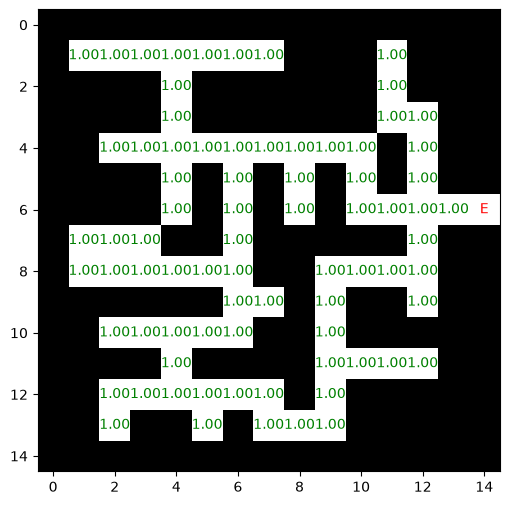

In [ ]:
# plot values
def plot_values(Maze, first_visit_values):
	states, exit_state, init_states = get_states_from_Maze(Maze)
	plt.figure(figsize=(15, 10))
	plt.imshow(Maze, cmap='gray', origin='upper')
	for idx, state in enumerate(states):
		if state[0] == exit_state[0] and state[1] == exit_state[1]: 
			continue  
		plt.text(state[1], state[0], f'{first_visit_values[idx]:.2f}', ha='center', va='center', color='green')
	
	plt.text(exit_state[1], exit_state[0], 'E', ha='center', va='center', color='red')
	# for state in init_states:
	# 	print(f"Initial State: {state}")  # Print the initial state coordinates
	# 	plt.text(state[1], state[0], f'{first_visit_values[states.index((state[0], state[1]))]:.2f}', ha='center', va='center', color='blue')	


plot_values(Maze,  first_visit_values)

## Monte Carlo exploring start

In [68]:


def monte_carlo_exploring(maze,gamma=0.9, iter_max=1000):
    states, exit_state, init_states = get_states_from_Maze(maze)
    pi = np.zeros(len(states), dtype=int)  # Initialize policy to always take action 0
    q_s_a = np.zeros((len(states), len(actions)))  # Initialize Q(s,a) to zero
    returns = {}  # Count of returns for each (s,a) pair

    for _ in range(iter_max):
        init_state = init_states[np.random.randint(len(init_states))]
        episode = generate_episode_from_policy(init_state, actions, maze, exit_state,pi=None, iter_max=iter_max)
        episode = list(map(process_episode, episode))  # Process the episode to get indices

        episode_states = set()
        G = 0
        visited_state_action_pairs = set()  # To track first visits of (state, action) pairs
        for t in reversed(range(len(episode))):
            state, action, reward, next_state = episode[t]
            episode_states.add(state)
            G = reward + gamma * G  # Update return G
            
            if (state, action) not in returns:
                returns[(state, action)] = []
                
            if (state, action) not in visited_state_action_pairs:
                visited_state_action_pairs.add((state, action))
                returns[(state, action)] += [G]
                
            q_s_a[state][action] = np.mean(returns[(state, action)])

        for s in episode_states:
            pi[s] = np.argmax(q_s_a[s])

    return pi, q_s_a

print("monte_carlo_exploring :")
pi, q_s_a = monte_carlo_exploring(Maze, gamma=0.9, iter_max=1000)
print("Policy (pi):")
print(pi)   

print("Action values (Q(s,a)): ")
print(q_s_a)

monte_carlo_exploring :
Policy (pi):
[1 1 1 2 3 3 3 2 2 2 2 1 2 1 1 1 1 1 1 1 1 2 2 0 0 0 2 2 0 0 0 1 1 1 1 0 1
 1 2 0 0 1 1 1 1 1 0 1 1 1 0 0 3 0 0 1 1 1 1 0 0 0 0 3 3 3 1 1 1 1 1 2 0 0
 0 1 1 0]
Action values (Q(s,a)): 
[[0.00000000e+00 6.75960077e-04 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 8.38848583e-04 0.00000000e+00 6.11942454e-04]
 [0.00000000e+00 1.31408528e-03 0.00000000e+00 6.64328117e-04]
 [0.00000000e+00 9.51058394e-04 2.73029193e-03 8.02761506e-04]
 [0.00000000e+00 5.42512706e-04 0.00000000e+00 1.40172269e-03]
 [0.00000000e+00 5.82143452e-04 0.00000000e+00 7.50300512e-04]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 6.32290653e-04]
 [0.00000000e+00 0.00000000e+00 9.49176798e-02 0.00000000e+00]
 [1.69841769e-03 0.00000000e+00 4.22187672e-03 0.00000000e+00]
 [8.62434203e-02 0.00000000e+00 1.34956794e-01 0.00000000e+00]
 [2.94199264e-03 0.00000000e+00 6.50868417e-03 0.00000000e+00]
 [1.04794546e-01 2.03482506e-01 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.000

State: (1, 1), Best Action: RIGHT
State: (1, 2), Best Action: RIGHT
State: (1, 3), Best Action: RIGHT
State: (1, 4), Best Action: DOWN
State: (1, 5), Best Action: LEFT
State: (1, 6), Best Action: LEFT
State: (1, 7), Best Action: LEFT
State: (1, 11), Best Action: DOWN
State: (2, 4), Best Action: DOWN
State: (2, 11), Best Action: DOWN
State: (3, 4), Best Action: DOWN
State: (3, 11), Best Action: RIGHT
State: (3, 12), Best Action: DOWN
State: (4, 2), Best Action: RIGHT
State: (4, 3), Best Action: RIGHT
State: (4, 4), Best Action: RIGHT
State: (4, 5), Best Action: RIGHT
State: (4, 6), Best Action: RIGHT
State: (4, 7), Best Action: RIGHT
State: (4, 8), Best Action: RIGHT
State: (4, 9), Best Action: RIGHT
State: (4, 10), Best Action: DOWN
State: (4, 12), Best Action: DOWN
State: (5, 4), Best Action: UP
State: (5, 6), Best Action: UP
State: (5, 8), Best Action: UP
State: (5, 10), Best Action: DOWN
State: (5, 12), Best Action: DOWN
State: (6, 4), Best Action: UP
State: (6, 6), Best Action: UP


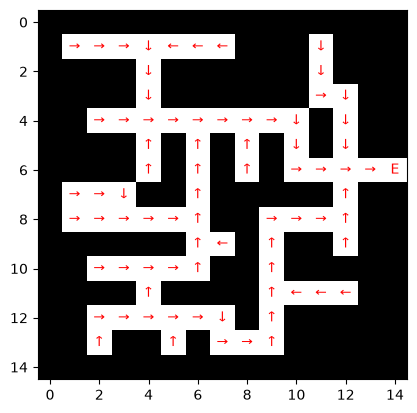

In [69]:
plot_policy(Maze, states, actions, pi)

## On policy first visit Monte Carlo control

In [70]:
def monte_carlo_fv_on_policy(maze, gamma, epsilon, iter_max=1000):
    states, exit_state, init_states = get_states_from_Maze(maze)
    pi = generate_random_e_soft_policy(states, actions, epsilon)  # Initialize a random epsilon-soft policy
    q_s_a = np.zeros((len(states), len(actions)))  # Initialize Q(s,a) to zero
    returns = {}  # Count of returns for each (s,a) pair

    for s in range(len(states)):
        for a in range(len(actions)):
            returns[(s, a)] = [] 
            
	

    for _ in range(iter_max):
        init_state = init_states[np.random.randint(len(init_states))]
        episode = generate_valide_episode(init_states, actions, maze, exit_state, max_iter=iter_max)
        episode = list(map(process_episode, episode))  # Process the episode to get indices

        visited = set()
        episode_states = set()
        G = 0
        for t in reversed(range(len(episode))):
            state, action, reward, next_state = episode[t]
            visited.add(state)
            episode_states.add(state)
            G = reward + (gamma * G)
            if (state, action) not in visited:
                visited.add((state, action))
                returns[(state, action)] += [G]
                q_s_a[state][action] = np.mean(returns[(state, action)])

        # Update policy to be epsilon-soft with respect to Q(s,a)
        for s in episode_states:
            best_action = np.argmax(q_s_a[s])
            if np.random.rand() < epsilon:
                pi[s] = np.random.choice(len(actions))  # Explore: choose a random action
            else:
                pi[s] = best_action  # Exploit: choose the best action
                
                

    return pi, q_s_a

print("monte_carlo_control first visit :")
gamma = 0.9
pi, q_s_a = monte_carlo_fv_on_policy(Maze, gamma, epsilon=0.1, iter_max=1000)
print("Policy (pi):")
print(pi)
print("Q(s,a):")
print(q_s_a)

monte_carlo_control first visit :
Policy (pi):
[1 1 1 2 3 3 3 2 2 2 2 0 2 1 1 1 1 1 1 3 1 2 2 0 0 0 3 2 0 0 0 1 1 1 1 0 1
 2 0 0 0 0 1 1 1 1 3 1 2 1 0 0 3 0 0 1 1 1 1 0 0 2 0 3 3 3 1 1 1 1 1 2 0 0
 0 1 1 0]
Q(s,a):
[[0.00000000e+00 6.55104379e-04 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 7.33279559e-04 0.00000000e+00 5.87928421e-04]
 [0.00000000e+00 9.22139700e-04 0.00000000e+00 5.55147989e-04]
 [0.00000000e+00 4.40847253e-04 1.88041397e-03 5.84204550e-04]
 [0.00000000e+00 1.36268907e-04 0.00000000e+00 6.78954505e-04]
 [0.00000000e+00 1.98741094e-04 0.00000000e+00 3.86444852e-04]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 3.31736366e-04]
 [0.00000000e+00 0.00000000e+00 8.10405006e-02 0.00000000e+00]
 [9.84285526e-04 0.00000000e+00 2.71091704e-03 0.00000000e+00]
 [7.22467706e-02 0.00000000e+00 1.07492376e-01 0.00000000e+00]
 [1.50306644e-03 0.00000000e+00 3.63170918e-03 0.00000000e+00]
 [7.73615336e-02 1.64209425e-01 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+

## Visualisation

In [71]:
_, exit_state, _ = get_states_from_Maze(Maze)
exit_state

array([ 6, 14])

State: (1, 1), Best Action: RIGHT
State: (1, 2), Best Action: RIGHT
State: (1, 3), Best Action: RIGHT
State: (1, 4), Best Action: DOWN
State: (1, 5), Best Action: LEFT
State: (1, 6), Best Action: LEFT
State: (1, 7), Best Action: LEFT
State: (1, 11), Best Action: DOWN
State: (2, 4), Best Action: DOWN
State: (2, 11), Best Action: DOWN
State: (3, 4), Best Action: DOWN
State: (3, 11), Best Action: UP
State: (3, 12), Best Action: DOWN
State: (4, 2), Best Action: RIGHT
State: (4, 3), Best Action: RIGHT
State: (4, 4), Best Action: RIGHT
State: (4, 5), Best Action: RIGHT
State: (4, 6), Best Action: RIGHT
State: (4, 7), Best Action: RIGHT
State: (4, 8), Best Action: LEFT
State: (4, 9), Best Action: RIGHT
State: (4, 10), Best Action: DOWN
State: (4, 12), Best Action: DOWN
State: (5, 4), Best Action: UP
State: (5, 6), Best Action: UP
State: (5, 8), Best Action: UP
State: (5, 10), Best Action: LEFT
State: (5, 12), Best Action: DOWN
State: (6, 4), Best Action: UP
State: (6, 6), Best Action: UP
Stat

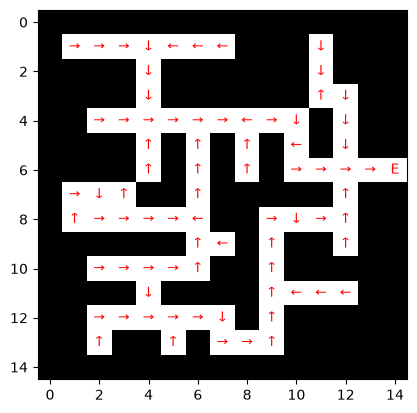

In [72]:


plot_policy(Maze, states, actions, pi)

# Temporal Difference methods